In [1]:
import sys
import os
import glob

# Get the absolute path to the parent directory
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Add hybrid_lasso to sys.path
sys.path.append(project_root)

# Now, import should work
from hybrid_lasso.model_ar_reg import AdaptiveRidgeRegression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

from lassonet import LassoNetRegressor
import seaborn as sns
import torch

In [40]:
def plot_nimo(ckpt, train_df, figsize1=(4, 3), figsize2=(1, 6), hidden_dim=None, name=None):
    if hidden_dim is None:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt)
    else:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt, hidden_dim=hidden_dim)

    beta = model.beta.detach().cpu().numpy()
    beta_0 = model.beta_0.detach().cpu().numpy()

    print(beta, beta_0)

    plt.figure(figsize=figsize1)
    plt.gca().set_axisbelow(True)

    feature_names = train_df.columns[:-1].tolist() + ["Intercept"]
    coefficients = np.append(beta, beta_0)
    plt.barh(feature_names, coefficients)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Feature Name")
    plt.title("Feature Coefficients of NIMO")
    if name is not None:
        plt.savefig(f"../{name}_nimo_coeff.pdf", dpi=300)
    plt.show()

    # Plot FC layer weights
    first_fc_layer = model.fc1.weight.detach().cpu().numpy()
    first_fc_layer = first_fc_layer[:, : len(train_df.columns) - 1]

    print(first_fc_layer.mean(0), first_fc_layer.std(0))

    plt.figure(figsize=figsize2)
    plt.imshow(first_fc_layer, aspect="auto", cmap="viridis")  # , vmin=-1, vmax=1)
    plt.colorbar(label="Weight Magnitude")
    plt.title("First FC Layer Weights")
    if first_fc_layer.shape[1] <= 5:
        plt.xticks(ticks=[0, first_fc_layer.shape[1] - 1], labels=[1, first_fc_layer.shape[1]])
    else:
        plt.xticks(
            ticks=np.arange(0, first_fc_layer.shape[1], 5),
            labels=np.arange(1, first_fc_layer.shape[1] + 1, 5),
        )
    plt.xlabel("Input Features")
    plt.ylabel("Neurons")
    if name is not None:
        plt.savefig(f"../{name}_fc_weights.pdf", dpi=300)
    plt.show()

    return coefficients, first_fc_layer

In [3]:
train_df = pd.read_csv("../data/synthetic_reg/setting1_wo_noise/train.csv")
val_df = pd.read_csv("../data/synthetic_reg/setting1_wo_noise/val.csv")
test_df = pd.read_csv("../data/synthetic_reg/setting1_wo_noise/test.csv")


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


X_train = train_df.drop(columns=["target"]).values
y_train = train_df["target"].values.astype(float)
X_val = val_df.drop(columns=["target"]).values
y_val = val_df["target"].values.astype(float)
X_test = test_df.drop(columns=["target"]).values
y_test = test_df["target"].values.astype(float)

MSE: 0.024
==> training with noise_injection=True
AdaptiveRidgeRegression(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (fc2): Linear(in_features=67, out_features=128, bias=True)
  (fc3): Linear(in_features=195, out_features=1, bias=True)
  (dropout2): Identity()
)
==> training with noise_injection=True


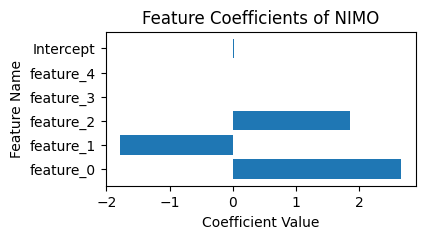

[ 0.04302632  0.0439931   0.01453052 -0.05356137 -0.03044126] [0.31121024 0.33648786 0.36685658 0.19215621 0.21947373]


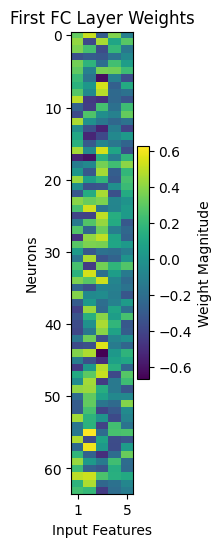

In [29]:
## Train our NIMO model and compare the results
expr_name = "ar_reg_setting1_no_fc_penalty_gamma0"

hybrid_pred = torch.load(f"../ckpts/predictions_{expr_name}.pt")[0]
pred_hybrid = np.array(hybrid_pred)

mse_nofc_penalty = mean_squared_error(test_df["target"], pred_hybrid)
print(f"MSE: {mse_nofc_penalty:.3f}")


model_ckpt = "../tb_logs/ar_reg_setting1_no_fc_penalty_gamma0/version_0/checkpoints/best_model_epoch=935.ckpt"

model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
print(model)

nimo_coeff_nofc_penalty, fc_weight_nofc_penalty = plot_nimo(
    model_ckpt, train_df, figsize1=(4, 2), figsize2=(1, 6)
)

MSE: 0.009
==> training with noise_injection=True
AdaptiveRidgeRegression(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (fc2): Linear(in_features=67, out_features=128, bias=True)
  (fc3): Linear(in_features=195, out_features=1, bias=True)
  (dropout2): Identity()
)
==> training with noise_injection=True


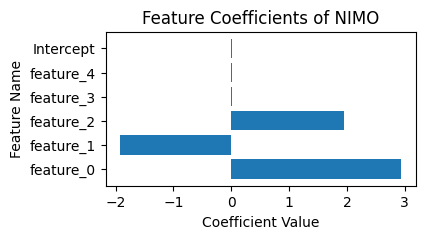

[ 1.3380041e-02  3.0441977e-02  7.8128763e-03 -9.8591430e-05
  7.4871910e-05] [0.15111512 0.2067671  0.22435604 0.00131844 0.00114511]


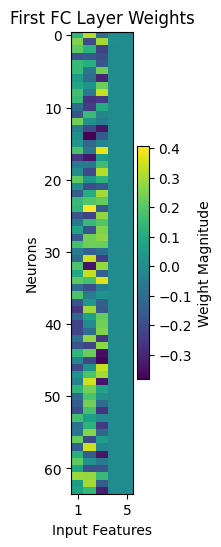

In [30]:
## Train our NIMO model and compare the results
expr_name = "ar_reg_setting1_with_fc_penalty_gamma0"

hybrid_pred = torch.load(f"../ckpts/predictions_{expr_name}.pt")[0]
pred_hybrid = np.array(hybrid_pred)

mse_wfc_penalty = mean_squared_error(test_df["target"], pred_hybrid)
print(f"MSE: {mse_wfc_penalty:.3f}")


model_ckpt = "../tb_logs/ar_reg_setting1_with_fc_penalty_gamma0/version_0/checkpoints/best_model_epoch=803.ckpt"

model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
print(model)

nimo_coeff_wfc_penalty, fc_weight_wfc_penalty = plot_nimo(
    model_ckpt, train_df, figsize1=(4, 2), figsize2=(1, 6)
)

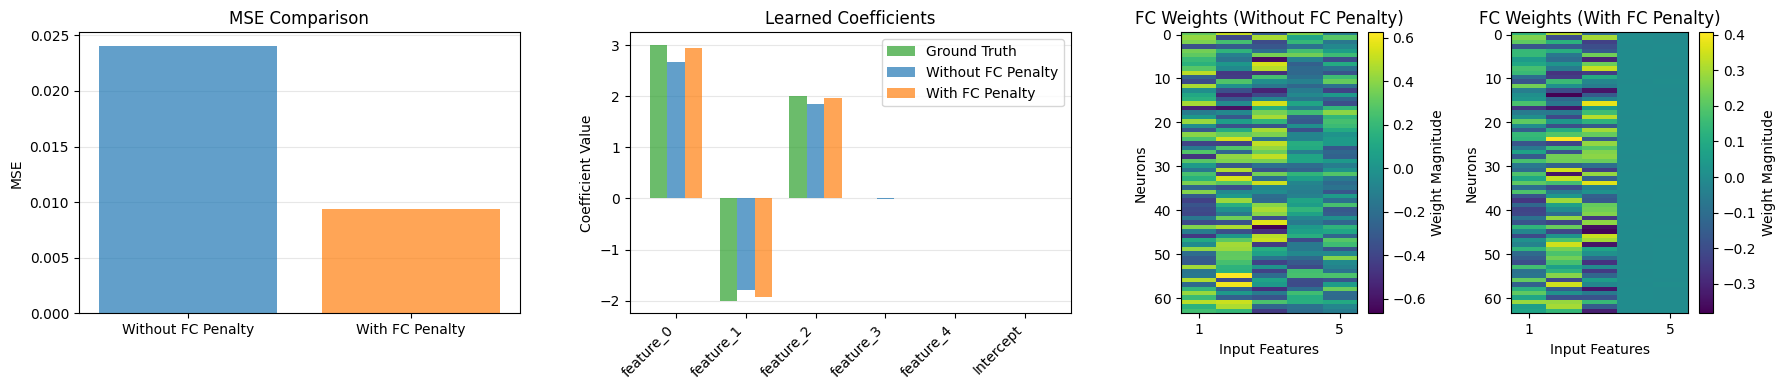

In [37]:
fig, axes = plt.subplots(
    1,
    4,
    figsize=(18, 4),
    gridspec_kw={"width_ratios": [2, 2, 1, 1]},  # Make last two subplots slim
)

# Plot 1: MSE comparison (bar plot)
ax1 = axes[0]
mse_values = [mse_nofc_penalty, mse_wfc_penalty]  # Update with actual MSE values
labels = ["Without FC Penalty", "With FC Penalty"]
colors = ["#1f77b4", "#ff7f0e"]
ax1.bar(labels, mse_values, color=colors, alpha=0.7)
ax1.set_ylabel("MSE")
ax1.set_title("MSE Comparison")
ax1.set_axisbelow(True)
ax1.grid(axis="y", alpha=0.3)

# Plot 2: Coefficients comparison (vertical bars)
ax2 = axes[1]
feature_names = train_df.columns[:-1].tolist() + ["Intercept"]
ground_truth = [3, -2, 2, 0, 0, 0]  # Ground truth coefficients + intercept
x = np.arange(len(feature_names))
width = 0.25

ax2.bar(x - width, ground_truth, width, label="Ground Truth", alpha=0.7, color="#2ca02c")
ax2.bar(x, nimo_coeff_nofc_penalty, width, label="Without FC Penalty", alpha=0.7, color="#1f77b4")
ax2.bar(
    x + width, nimo_coeff_wfc_penalty, width, label="With FC Penalty", alpha=0.7, color="#ff7f0e"
)
ax2.set_xticks(x)
ax2.set_xticklabels(feature_names, rotation=45, ha="right")
ax2.set_ylabel("Coefficient Value")
ax2.set_title("Learned Coefficients")
ax2.legend()
ax2.set_axisbelow(True)
ax2.grid(axis="y", alpha=0.3)

# Plot 3: FC weight matrix without FC penalty
ax3 = axes[2]
im1 = ax3.imshow(fc_weight_nofc_penalty, aspect="auto", cmap="viridis")
plt.colorbar(im1, ax=ax3, label="Weight Magnitude")
ax3.set_title("FC Weights (Without FC Penalty)")
ax3.set_ylabel("Neurons")
ax3.set_xlabel("Input Features")
if fc_weight_nofc_penalty.shape[1] <= 5:
    ax3.set_xticks([0, fc_weight_nofc_penalty.shape[1] - 1])
    ax3.set_xticklabels([1, fc_weight_nofc_penalty.shape[1]])
else:
    ax3.set_xticks(np.arange(0, fc_weight_nofc_penalty.shape[1], 5))
    ax3.set_xticklabels(np.arange(1, fc_weight_nofc_penalty.shape[1] + 1, 5))

# Plot 4: FC weight matrix with FC penalty
ax4 = axes[3]
im2 = ax4.imshow(fc_weight_wfc_penalty, aspect="auto", cmap="viridis")
plt.colorbar(im2, ax=ax4, label="Weight Magnitude")
ax4.set_title("FC Weights (With FC Penalty)")
ax4.set_ylabel("Neurons")
ax4.set_xlabel("Input Features")
if fc_weight_wfc_penalty.shape[1] <= 5:
    ax4.set_xticks([0, fc_weight_wfc_penalty.shape[1] - 1])
    ax4.set_xticklabels([1, fc_weight_wfc_penalty.shape[1]])
else:
    ax4.set_xticks(np.arange(0, fc_weight_wfc_penalty.shape[1], 5))
    ax4.set_xticklabels(np.arange(1, fc_weight_wfc_penalty.shape[1] + 1, 5))

plt.tight_layout()
plt.savefig("../figs/ablation_fc_sparse_penalty.pdf", dpi=300)
plt.show()